In [46]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import umap
import kagglehub
import os

clothes_dict = {
    0: 'T-shirt/top',
    1: 'Trouser',
    2: 'Pullover',
    3: 'Dress',
    4: 'Coat',
    5: 'Sandal',
    6: 'Shirt',
    7: 'Sneaker',
    8: 'Bag',
    9: 'Ankle boot'
}

file_path = "fashion-mnist_train.csv"

dataset_path = kagglehub.dataset_download("zalando-research/fashionmnist")
print(f"Dane pobrane do: {dataset_path}")

# 2. Zbuduj pełną ścieżkę do konkretnego pliku CSV
csv_path = os.path.join(dataset_path, "fashion-mnist_train.csv")

# 3. Wczytaj dane standardowym narzędziem Pandas
df = pd.read_csv(csv_path)

100%|██████████| 68.8M/68.8M [00:02<00:00, 26.3MB/s]

Extracting files...


Dane pobrane do: C:\Users\jacek\.cache\kagglehub\datasets\zalando-research\fashionmnist\versions\4


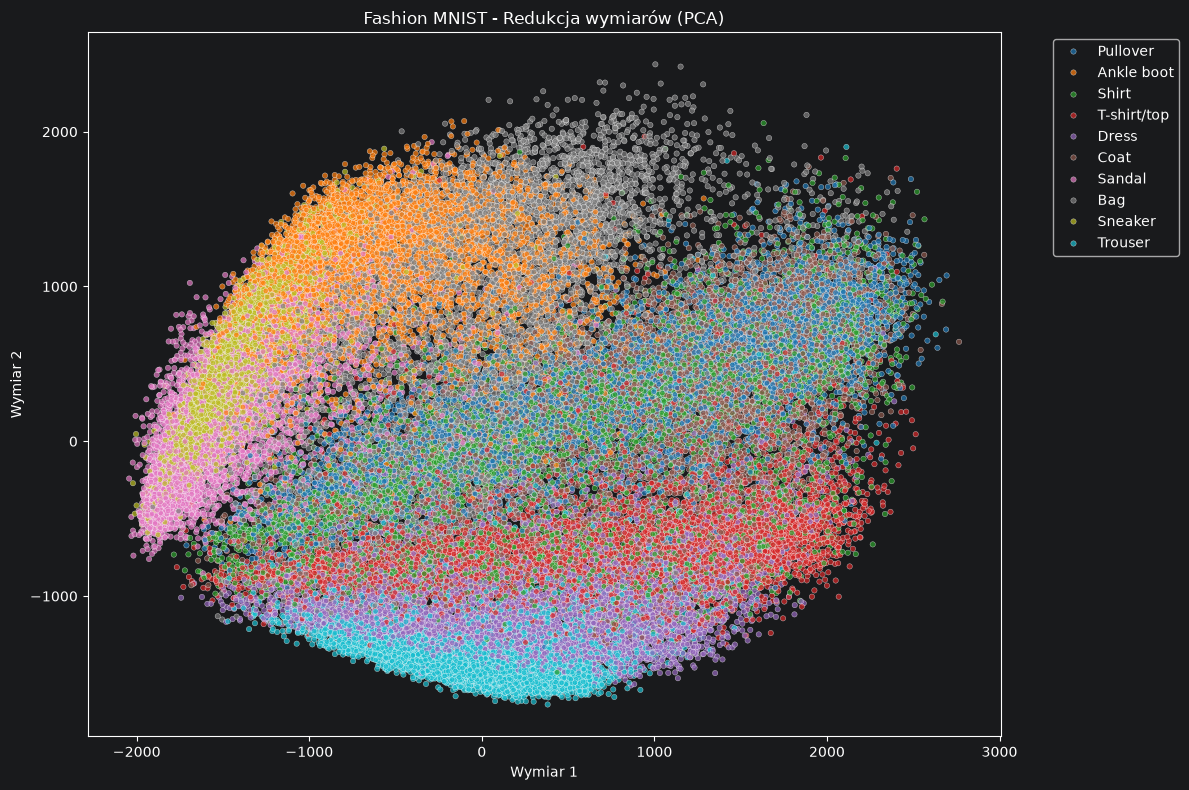

In [47]:

labels = df['label']
df_pixel_only = df.drop('label',axis=1)

pca = PCA(n_components=2)
data_pca = pca.fit_transform(df_pixel_only)

df_chart = pd.DataFrame(data_pca, columns=['Wymiar 1', 'Wymiar 2'])
df_chart['label'] = labels.map(clothes_dict)

plt.figure(figsize=(12, 8))

sns.scatterplot(
    x='Wymiar 1',
    y='Wymiar 2',
    hue='label',
    palette='tab10',
    data=df_chart,
    alpha=0.7,
    s=15
)

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title('Fashion MNIST - Redukcja wymiarów (PCA)')
plt.tight_layout()
plt.show()


In [ ]:
tsne = TSNE(n_components=2, perplexity=30.0, random_state=42)
dane_tsne = tsne.fit_transform(df_pixel_only)

df_chart = pd.DataFrame(dane_tsne, columns=['Wymiar 1', 'Wymiar 2'])
df_chart['label'] = labels.map(clothes_dict)

plt.figure(figsize=(12, 8))

sns.scatterplot(
    x='Wymiar 1',
    y='Wymiar 2',
    hue='label',
    palette='tab10',
    data=df_chart,
    alpha=0.7,
    s=15
)

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title('Fashion MNIST - Redukcja wymiarów (tsne)')
plt.tight_layout()
plt.show()

In [ ]:
reducer = umap.UMAP(n_components=2, random_state=42)

dane_umap = reducer.fit_transform(df_pixel_only)

df_chart_umap = pd.DataFrame(dane_umap, columns=['Wymiar 1', 'Wymiar 2'])

df_chart_umap['label'] = labels.map(clothes_dict).values

plt.figure(figsize=(12, 8))

sns.scatterplot(
    x='Wymiar 1',
    y='Wymiar 2',
    hue='label',
    palette='tab10',
    data=df_chart_umap,
    alpha=0.7,
    s=15
)

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title('Fashion MNIST - Redukcja wymiarów (UMAP)')
plt.tight_layout()
plt.show()

In [ ]:
srednie_wg_klas = df.groupby('label').mean()

fig, axes = plt.subplots(2, 5, figsize=(16, 6))

for etykieta, ax in enumerate(axes.flat):
    wektor_pikseli = srednie_wg_klas.loc[etykieta].values
    obraz_28x28 = wektor_pikseli.reshape(28, 28)


    ax.imshow(obraz_28x28, cmap='gray')
    ax.set_title(clothes_dict[etykieta])
    ax.axis('off')

plt.suptitle('Średni wygląd każdego elementu ubioru', fontsize=16)
plt.tight_layout()
plt.show()


użył bym MLPClassifier
hipoteza dotyczny zmiany funkjci aktywacji
w sklearn mozna to zrobic ustawijac parametr activation
zastapienie nielinowje funkcji aktywacji na liniowa sprawilo by ze model staracił by umiejetnosc uczenia sie